# 01 — Exploratory Data Analysis
### The hidden cost of "Regular" mutual fund plans

**The problem.** Almost every Indian mutual fund is sold in two forms of the
*exact same portfolio*:

- a **Regular plan**, which pays a yearly commission to whoever sold it to you
  (your bank, an app, an agent), skimmed out of the fund itself, and
- a **Direct plan**, which pays no commission.

Same fund manager, same stocks, same everything — the only difference is the
commission. SEBI made Direct plans mandatory in **January 2013**, yet most
retail investors have never heard of them and silently sit in the costlier
Regular version.

**The clean idea behind this project.** Because the two plans hold an *identical*
portfolio, the **difference in their returns is a direct, unarguable measurement
of the commission drag** — no modelling assumptions required. AMFI publishes the
daily NAV (price) of both plans for every fund, so we can simply line them up and
read off the gap.

**This notebook (EDA)** profiles the raw data: how many schemes exist, how messy
the names are, how we tell the two plans apart, and how many funds we can actually
pair up for a fair comparison. We finish with the concrete questions the rest of
the project answers.

In [1]:
import sys
from pathlib import Path

# Make `import src` work no matter where Jupyter was launched from.
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src import download, cleaning, plotting
from src import paths

plotting.set_style()
pd.set_option("display.max_colwidth", 90)
print("Project root:", paths.ROOT)

Project root: /Users/shauryakesarwani/Desktop/prjcts/hidden-mutual-fund-fees


## 1. Load the raw scheme list

The data source is the free, public **mfapi.in** API, which mirrors AMFI's
official daily NAV files. Its `/mf` endpoint returns one row per scheme. We cache
the response to `data/raw/scheme_list.json` so the project is fully reproducible
(re-running never silently changes the dataset underneath the analysis).

In [2]:
raw_list = download.fetch_scheme_list()      # cached after first call
schemes = pd.DataFrame(raw_list)
print(f"{len(schemes):,} schemes in the raw AMFI universe")
schemes.head()

37,631 schemes in the raw AMFI universe


,schemeCode,schemeName,isinGrowth,isinDivReinvestment
0,100027,Grindlays Super Saver Income Fund-GSSIF-Half Yearly Dividend,None,None
1,100028,Grindlays Super Saver Income Fund-GSSIF-Quaterly Dividend,None,None
2,100029,Grindlays Super Saver Income Fund-GSSIF-Growth,None,None
3,100030,Grindlays Super Saver Income Fund-GSSIF-Annual Dividend,None,None
4,100031,Grindlays Super Saver Income Fund-GSSIF - ST-Dividend,None,None


## 2. Profile: shape, types, missingness

A quick structural profile — the first thing any analyst should document.

In [3]:
print("Shape:", schemes.shape)
print("\nDtypes:")
print(schemes.dtypes)
print("\nMissing values per column:")
print(schemes.isna().sum())
print("\n% missing:")
print((schemes.isna().mean() * 100).round(1))

Shape: (37631, 4)

Dtypes:
schemeCode              int64
schemeName             object
isinGrowth             object
isinDivReinvestment    object
dtype: object

Missing values per column:
schemeCode                 0
schemeName                 0
isinGrowth             29222
isinDivReinvestment    33498
dtype: int64

% missing:
schemeCode              0.0
schemeName              0.0
isinGrowth             77.7
isinDivReinvestment    89.0
dtype: float64


The two ISIN columns are heavily missing — they're blank for old/defunct
schemes and for dividend sub-variants. We won't rely on them; the **scheme name**
is the field that actually carries the information we need (plan + option), so the
real work is parsing that messy free-text column.

## 3. Just how messy are the scheme names?

Everything we need — *is this a Direct or Regular plan? a Growth or dividend
option?* — is buried in inconsistent free text. Below are real examples of the
formatting chaos we have to survive.

In [4]:
samples = [
    "Axis ELSS Tax Saver Fund - Direct Plan - Growth Option",
    "Helios Balanced Advantage Fund- Regular Plan- Growth Option",   # no spaces around dash
    "360 ONE LIQUID FUND DIRECT PLAN  GROWTH",                       # all caps, double space, no dashes
    "SBI Bluechip Fund - Regular Plan - IDCW",                       # dividend option
    "HDFC Top 100 Fund (erstwhile HDFC Top 200) - Direct - Growth",  # parenthetical rename
    "ICICI Prudential Value Discovery Fund - Growth",                # legacy: no explicit plan token
]
for s in samples:
    print(f"plan={cleaning.classify_plan(s):<8} option={cleaning.classify_option(s):<8} | {s}")

plan=Direct   option=Growth   | Axis ELSS Tax Saver Fund - Direct Plan - Growth Option
plan=Regular  option=Growth   | Helios Balanced Advantage Fund- Regular Plan- Growth Option
plan=Direct   option=Growth   | 360 ONE LIQUID FUND DIRECT PLAN  GROWTH
plan=Regular  option=IDCW     | SBI Bluechip Fund - Regular Plan - IDCW
plan=Direct   option=Growth   | HDFC Top 100 Fund (erstwhile HDFC Top 200) - Direct - Growth
plan=Unknown  option=Growth   | ICICI Prudential Value Discovery Fund - Growth


Note the traps we have to handle:

- **Separators vary**: `' - '`, `'- '`, `' '`, none at all.
- **Casing varies**: `Growth` vs `GROWTH`.
- **Parenthetical renames** (`(erstwhile ...)`) appear on one plan but not the other.
- **Legacy schemes** sometimes carry *no* explicit `Direct`/`Regular` token.

Our `src/cleaning.py` normaliser strips parentheticals, rename clauses, and the
plan/option tokens, then collapses punctuation — producing a stable *match key*
that is identical for a fund's two plans.

In [5]:
# Classify the whole universe and look at the breakdown.
schemes["plan"] = schemes["schemeName"].map(cleaning.classify_plan)
schemes["option"] = schemes["schemeName"].map(cleaning.classify_option)

print("Plan breakdown:")
print(schemes["plan"].value_counts(), "\n")
print("Option breakdown:")
print(schemes["option"].value_counts())

Plan breakdown:
plan
Unknown    15231
Direct     12483
Regular     9917
Name: count, dtype: int64 

Option breakdown:
option
IDCW       20780
Growth     14094
Unknown     2757
Name: count, dtype: int64


Two things stand out and directly shape our cleaning rules:

1. A large block of schemes are **dividend/IDCW** options. We exclude these — a
   dividend payout drops the NAV on the pay date, which would corrupt a
   NAV-based return calculation. We keep **Growth** plans only, where all returns
   are reflected in the NAV.
2. A chunk of schemes have an **`Unknown` plan** — mostly legacy names without an
   explicit `Direct`/`Regular` token. We deliberately *exclude* these rather than
   guess, trading some coverage for correctness (detailed in notebook 02).

## 4. Pair each Direct plan with its Regular twin

This is the heart of the dataset. For every fund we want the **Direct-Growth** and
**Regular-Growth** plan of the *same* portfolio, matched on the normalised key.
To keep the comparison clean, we require exactly one candidate on each side.

In [6]:
pairs = cleaning.build_pairs(raw_list)
print(f"{len(pairs):,} funds successfully paired (Direct-Growth <-> Regular-Growth)")
print(f"across ~{pairs['fund_name'].str.split().str[0].nunique()} fund houses\n")
pairs[["fund_name", "direct_code", "regular_code"]].head(10)

3,288 funds successfully paired (Direct-Growth <-> Regular-Growth)
across ~91 fund houses



,fund_name,direct_code,regular_code
0,360 ONE Balanced Hybrid Fund,152076,152075
1,360 ONE Dynamic Bond Fund,122715,122612
2,360 ONE ELSS Tax Saver Nifty 50 Index Fund,151165,151164
3,360 ONE FLEXICAP FUND,151796,151799
4,360 ONE Focused Fund,131580,131578
5,360 ONE LIQUID FUND,125345,125259
6,360 ONE Multi Asset Allocation Fund,153774,153772
7,360 ONE Overnight Fund,153703,153700
8,360 ONE QUANT FUND,149318,149317
9,ADITYA BIRLA SUN LIFE BAL BHAVISHYA YOJNA,146407,146409


In [7]:
# Spot-check that pairs really are the same fund, two plans.
pairs[["direct_name", "regular_name"]].sample(4, random_state=7)

,direct_name,regular_name
283,Aditya Birla Sun Life Income Plus Arbitrage Active FOF- Direct Plan - Growth Option,Aditya Birla Sun Life Income Plus Arbitrage Active FOF- Regular Plan - Growth Option
474,Axis Retirement Fund - Aggressive Plan - Direct Growth,Axis Retirement Fund - Aggressive Plan - Regular Growth
883,DSP BlackRock FMP - Series 108 -12M (Maturity Date 18-Aug-2016) - Direct Plan - Growth...,DSP BlackRock FMP - Series 108 -12M (Maturity Date 18-Aug-2016) - Regular Plan - Growt...
2053,Mirae Asset Nifty 50 Index Fund - Direct Plan - Growth,Mirae Asset Nifty 50 Index Fund - Regular Plan - Growth


## 5. Teaser: what the gap looks like for one fund

Before any aggregation, let's *see* the effect on a single large equity fund.
We plot ₹100 invested in the Direct vs the Regular plan on the same start date.
Identical portfolio — yet the lines drift apart, and the gap **is** the commission.

Example fund: Axis Midcap Fund


/Users/shauryakesarwani/Desktop/prjcts/hidden-mutual-fund-fees/src/plotting.py:44: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from current font.
  fig.savefig(paths.FIGURES / f"{name}.png")


/Users/shauryakesarwani/Desktop/prjcts/hidden-mutual-fund-fees/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


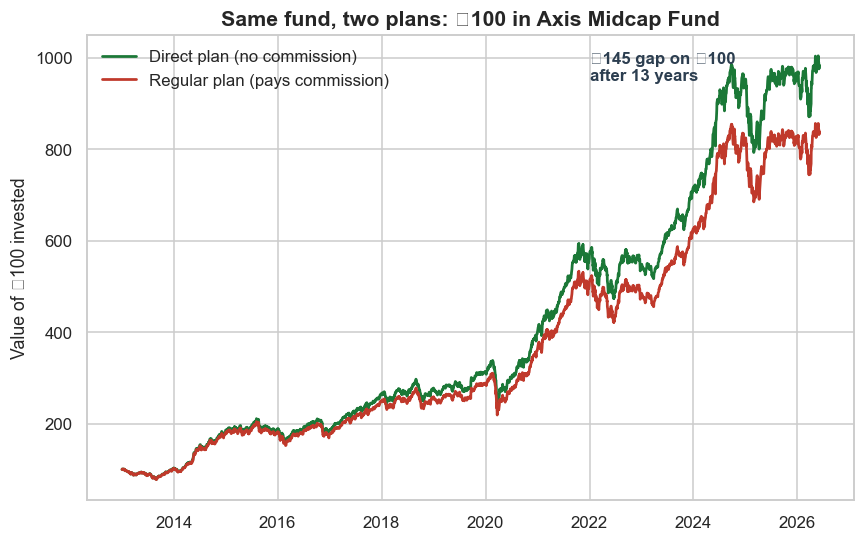

Direct ended at 983.7, Regular at 838.8 (started both at 100).


In [8]:
# Pick a well-known equity fund with long history (robust fallback chain).
candidates = ["Axis Midcap Fund", "Invesco India Contra Fund", "DSP Large Cap Fund"]
example = None
for c in candidates:
    hit = pairs[pairs["fund_name"].str.contains(c, case=False, regex=False)]
    if len(hit):
        example = hit.iloc[0]
        break
if example is None:                                   # last-resort fallback
    example = pairs[pairs["fund_name"].str.contains("Midcap|Large Cap", case=False)].iloc[0]
print("Example fund:", example["fund_name"])

d_pay = download.fetch_scheme_nav(example["direct_code"])
r_pay = download.fetch_scheme_nav(example["regular_code"])
d = cleaning.nav_payload_to_series(d_pay)
r = cleaning.nav_payload_to_series(r_pay)

# Common window, both rebased to 100.
start = max(d.index[0], r.index[0])
d, r = d[d.index >= start], r[r.index >= start]
d100, r100 = d / d.iloc[0] * 100, r / r.iloc[0] * 100

fig, ax = plt.subplots()
ax.plot(d100.index, d100, color=plotting.PALETTE["direct"], lw=1.8, label="Direct plan (no commission)")
ax.plot(r100.index, r100, color=plotting.PALETTE["regular"], lw=1.8, label="Regular plan (pays commission)")
ax.set_title(f"Same fund, two plans: ₹100 in {example['fund_name']}")
ax.set_ylabel("Value of ₹100 invested")
ax.set_xlabel("")
gap = d100.iloc[-1] - r100.iloc[-1]
ax.annotate(f"₹{gap:.0f} gap on ₹100\nafter {(d.index[-1]-start).days/365.25:.0f} years",
            xy=(d100.index[-1], d100.iloc[-1]), xytext=(-150, -10),
            textcoords="offset points", fontweight="bold", color=plotting.PALETTE["accent"])
ax.legend(loc="upper left")
plotting.save_fig(fig, "01_teaser_one_fund")
plt.show()
print(f"Direct ended at {d100.iloc[-1]:.1f}, Regular at {r100.iloc[-1]:.1f} (started both at 100).")

Same stocks, same manager — the Regular investor simply ends up with less,
every year, forever. On ₹100 the gap looks small; the rest of the project shows
what it becomes on a real SIP compounded over a working life.

## 6. Questions this project will answer

1. **How big is the hidden fee?** What's the typical annual return gap (drag)
   between Regular and Direct plans across all funds? *(nb 03)*
2. **Where does it bite hardest?** Which fund categories and fund houses have the
   largest drag? *(nb 03)*
3. **Is it a fixed toll or performance-linked?** Does the gap depend on how well
   the fund does, or is it a flat tax regardless? *(nb 03)*
4. **What does it cost a real person?** Translated onto a monthly SIP held for a
   working life, how many rupees does the Regular plan quietly cost? *(nb 03)*
5. **Is the gap statistically real, and what explains its size?** A paired
   hypothesis test and a regression on fund characteristics. *(nb 04)*

**Next:** `02_cleaning` builds the analysis-ready dataset and documents every
decision, then `03_analysis` and `04_modeling` answer the questions above.